#Import libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler



#Load Dataset

In [4]:
df=pd.read_csv("/content/drive/MyDrive/ICT/adult_dataset.csv")
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,NaN,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13.0,United-States,<=50K
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,<=50K
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,<=50K
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K


In [5]:
print("Shape of the dataset: ",df.shape)

Shape of the dataset:  (48842, 15)


In [6]:
print(df.columns)

Index(['age', 'workclass', 'fnlwgt', 'education', 'education-num',
       'marital-status', 'occupation', 'relationship', 'race', 'sex',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
       'income'],
      dtype='object')


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             46400 non-null  float64
 1   workclass       45480 non-null  object 
 2   fnlwgt          48842 non-null  int64  
 3   education       48842 non-null  object 
 4   education-num   48842 non-null  int64  
 5   marital-status  48842 non-null  object 
 6   occupation      45485 non-null  object 
 7   relationship    48842 non-null  object 
 8   race            48842 non-null  object 
 9   sex             48842 non-null  object 
 10  capital-gain    48842 non-null  int64  
 11  capital-loss    48842 non-null  int64  
 12  hours-per-week  46400 non-null  float64
 13  native-country  46137 non-null  object 
 14  income          48842 non-null  object 
dtypes: float64(2), int64(4), object(9)
memory usage: 5.6+ MB


In [8]:
df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,46400.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,46400.000000
mean,38.679116,1.896641e+05,10.078089,1079.067626,87.502314,40.448599
std,13.952954,1.056040e+05,2.570973,7452.019058,403.004552,12.646992
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,255.000000,1.490400e+06,16.000000,99999.000000,4356.000000,250.000000


In [9]:
df.isna().sum()

,0
age,2442
workclass,3362
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,3357
relationship,0
race,0
sex,0


In [10]:
df.isna().sum()/len(df)*100

,0
age,4.999795
workclass,6.883420
fnlwgt,0.000000
education,0.000000
education-num,0.000000
marital-status,0.000000
occupation,6.873183
relationship,0.000000
race,0.000000
sex,0.000000


In [11]:
#Check duplicated rows
print("No of duplicated rows: ",df.duplicated().sum())

No of duplicated rows:  16


In [12]:
print(df["income"].value_counts())

income
<=50K     24720
<=50K.    12435
>50K       7841
>50K.      3846
Name: count, dtype: int64


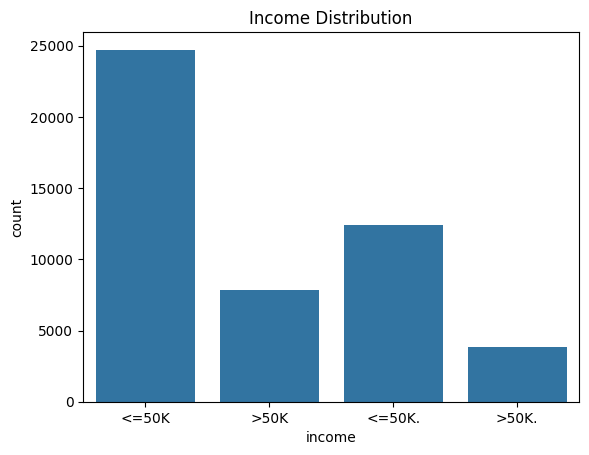

In [13]:
sns.countplot(x="income",data=df)
plt.title("Income Distribution")
plt.show()

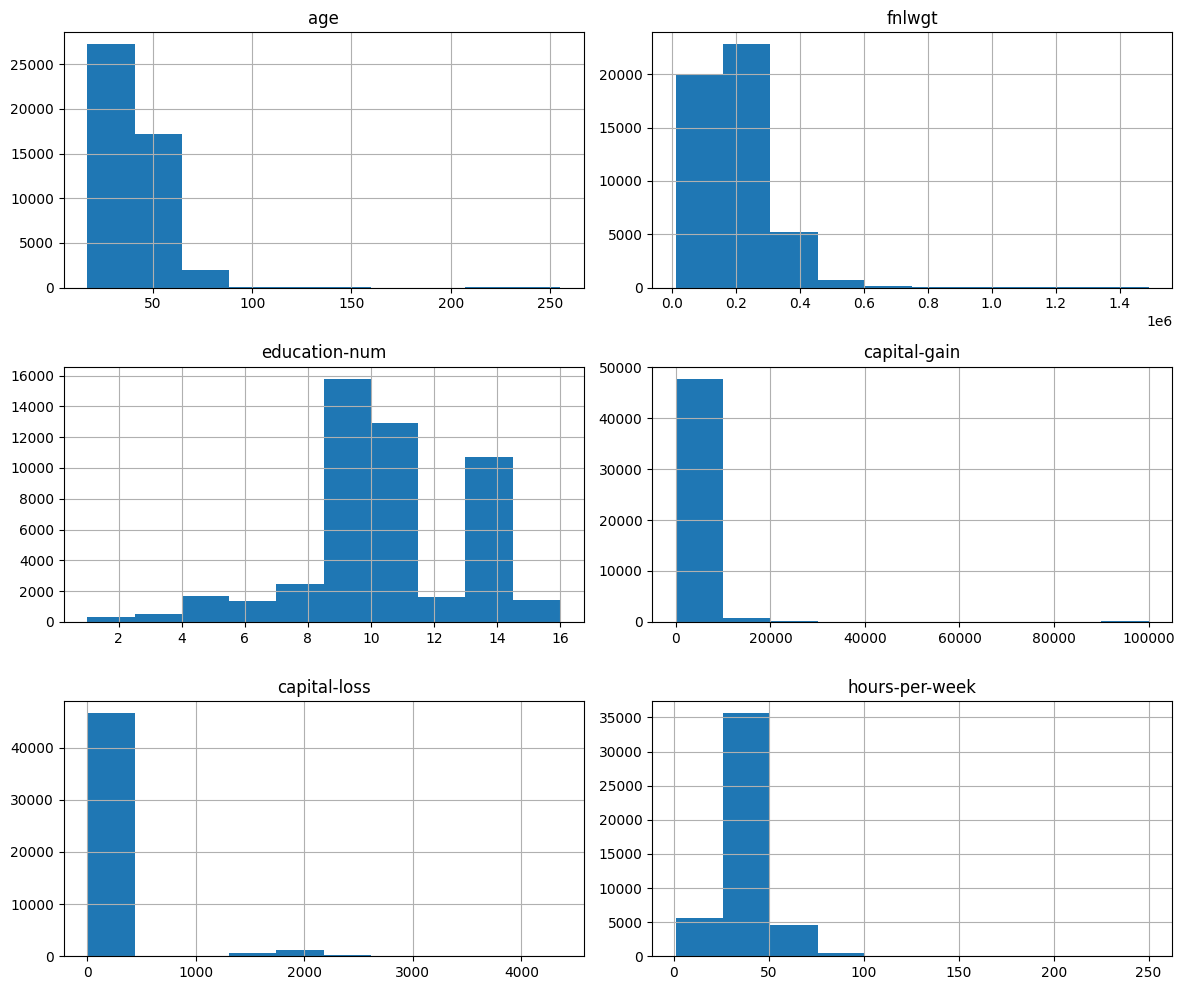

In [14]:
df.hist(figsize=(12, 10))
plt.tight_layout()
plt.show()

In [15]:
print("Question marks in each column:")
print((df == "?").sum())

Question marks in each column:
age                  0
workclass         1763
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        1758
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week       0
native-country     555
income               0
dtype: int64


In [16]:
df.replace("?", np.nan, inplace=True)

In [17]:
print(df.isnull().sum())

age               2442
workclass         5125
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        5115
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week    2442
native-country    3260
income               0
dtype: int64


In [18]:
print("Numerical columns:")
print(df.select_dtypes(include=np.number).columns)

print("\nCategorical columns:")
print(df.select_dtypes(include="object").columns)

Numerical columns:
Index(['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss',
       'hours-per-week'],
      dtype='object')

Categorical columns:
Index(['workclass', 'education', 'marital-status', 'occupation',
       'relationship', 'race', 'sex', 'native-country', 'income'],
      dtype='object')


In [19]:
from sklearn.impute import SimpleImputer

# Identify numerical and categorical columns
numerical_cols = df.select_dtypes(include=np.number).columns
categorical_cols = df.select_dtypes(include="object").columns

# Fill missing numerical values using median
num_imputer = SimpleImputer(strategy="median")
df[numerical_cols] = num_imputer.fit_transform(df[numerical_cols])

# Fill missing categorical values using mode
cat_imputer = SimpleImputer(strategy="most_frequent")
df[categorical_cols] = cat_imputer.fit_transform(df[categorical_cols])

# Check missing values
print(df.isnull().sum())

age               0
workclass         0
fnlwgt            0
education         0
education-num     0
marital-status    0
occupation        0
relationship      0
race              0
sex               0
capital-gain      0
capital-loss      0
hours-per-week    0
native-country    0
income            0
dtype: int64


In [20]:
# Clean the income target labels
df['income'] = df['income'].str.strip().str.rstrip('.')

# Check the cleaned labels
print(df['income'].value_counts())

income
<=50K    37155
>50K     11687
Name: count, dtype: int64


In [21]:
# Check duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 44


In [22]:
# Remove duplicate rows
df = df.drop_duplicates()

# Check the dataset shape
print("Shape after removing duplicates:", df.shape)

# Verify duplicates are removed
print("Remaining duplicate rows:", df.duplicated().sum())

Shape after removing duplicates: (48798, 15)
Remaining duplicate rows: 0


In [23]:
# Separate features and target
X = df.drop('income', axis=1)
y = df['income']


In [24]:
# Check the shapes
print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

Features (X) shape: (48798, 14)
Target (y) shape: (48798,)


In [25]:
# Display the target categories
print("\nTarget categories:")
print(y.value_counts())


Target categories:
income
<=50K    37117
>50K     11681
Name: count, dtype: int64


#Train-Test split

In [26]:
#Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Check the shapes
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (39038, 14)
X_test shape: (9760, 14)
y_train shape: (39038,)
y_test shape: (9760,)


In [27]:
from sklearn.preprocessing import OneHotEncoder

# Identify categorical and numerical columns
categorical_cols = X_train.select_dtypes(include=['object']).columns
numerical_cols = X_train.select_dtypes(include=np.number).columns

# Create the encoder
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

# Fit on training data and transform both datasets
X_train_cat = encoder.fit_transform(X_train[categorical_cols])
X_test_cat = encoder.transform(X_test[categorical_cols])

# Keep numerical features
X_train_num = X_train[numerical_cols].to_numpy()
X_test_num = X_test[numerical_cols].to_numpy()

# Combine numerical and encoded categorical features
X_train_encoded = np.concatenate([X_train_num, X_train_cat], axis=1)
X_test_encoded = np.concatenate([X_test_num, X_test_cat], axis=1)

print("Encoded X_train shape:", X_train_encoded.shape)
print("Encoded X_test shape:", X_test_encoded.shape)

Encoded X_train shape: (39038, 104)
Encoded X_test shape: (9760, 104)


In [28]:
# Convert income labels into numerical values
y_train_encoded = y_train.map({'<=50K': 0, '>50K': 1})
y_test_encoded = y_test.map({'<=50K': 0, '>50K': 1})

# Check the target values
print("Training target values:")
print(y_train_encoded.value_counts())

print("\nTesting target values:")
print(y_test_encoded.value_counts())

Training target values:
income
0    29693
1     9345
Name: count, dtype: int64

Testing target values:
income
0    7424
1    2336
Name: count, dtype: int64


In [29]:
scaler = StandardScaler()

# Scale numerical features using training data
X_train_num_scaled = scaler.fit_transform(X_train_num)

# Scale testing numerical features using the same scaler
X_test_num_scaled = scaler.transform(X_test_num)

# Combine scaled numerical features with encoded categorical features
X_train_final = np.concatenate(
    [X_train_num_scaled, X_train_cat], axis=1
)

X_test_final = np.concatenate(
    [X_test_num_scaled, X_test_cat], axis=1
)

# Check the final shapes
print("Final training data shape:", X_train_final.shape)
print("Final testing data shape:", X_test_final.shape)

Final training data shape: (39038, 104)
Final testing data shape: (9760, 104)


In [30]:
# Check data types and shapes
print("Training features:", X_train_final.shape)
print("Testing features:", X_test_final.shape)

print("Training target:", y_train_encoded.shape)
print("Testing target:", y_test_encoded.shape)

print("\nFeature data type:", X_train_final.dtype)
print("Target data type:", y_train_encoded.dtype)

print("\nMissing values in training features:",
      np.isnan(X_train_final).sum())

print("Missing values in testing features:",
      np.isnan(X_test_final).sum())

Training features: (39038, 104)
Testing features: (9760, 104)
Training target: (39038,)
Testing target: (9760,)

Feature data type: float64
Target data type: int64

Missing values in training features: 0
Missing values in testing features: 0


#Tensorflow

In [31]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

model = Sequential([
    Dense(64, activation='relu', input_shape=(104,)),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         6,720 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,833 (34.50 KB)

 Trainable params: 8,833 (34.50 KB)

 Non-trainable params: 0 (0.00 B)

In [32]:
history = model.fit(
    X_train_final,
    y_train_encoded,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/10
976/976 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8433 - loss: 0.3353 - val_accuracy: 0.8452 - val_loss: 0.3251
Epoch 2/10
976/976 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8549 - loss: 0.3101 - val_accuracy: 0.8563 - val_loss: 0.3204
Epoch 3/10
976/976 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8576 - loss: 0.3067 - val_accuracy: 0.8548 - val_loss: 0.3164
Epoch 4/10
976/976 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8582 - loss: 0.3041 - val_accuracy: 0.8530 - val_loss: 0.3257
Epoch 5/10
976/976 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8580 - loss: 0.3015 - val_accuracy: 0.8521 - val_loss: 0.3176
Epoch 6/10
976/976 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8610 - loss: 0.2984 - val_accuracy: 0.8527 - val_loss: 0.3171
Epoch 7/10
976/976 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8622 - loss: 0.2962 - val_accuracy: 0.8507 - val_loss: 0.3199
Epoch 8/10
976/976 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8614 - loss: 0.2940 - val_accuracy: 0.

In [33]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred_prob = model.predict(X_test_final)
y_pred = (y_pred_prob > 0.5).astype(int).ravel()

print("Accuracy:", accuracy_score(y_test_encoded, y_pred))
print("\nClassification Report:\n", classification_report(y_test_encoded, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test_encoded, y_pred))

305/305 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Accuracy: 0.8607581967213115

Classification Report:
               precision    recall  f1-score   support

           0       0.90      0.92      0.91      7424
           1       0.73      0.66      0.69      2336

    accuracy                           0.86      9760
   macro avg       0.81      0.79      0.80      9760
weighted avg       0.86      0.86      0.86      9760


Confusion Matrix:
 [[6865  559]
 [ 800 1536]]


#Pytorch

In [34]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

X_train_tensor = torch.tensor(X_train_final, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_final, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train_encoded.to_numpy(), dtype=torch.long)
y_test_tensor = torch.tensor(y_test_encoded.to_numpy(), dtype=torch.long)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

print("Training data:", X_train_tensor.shape)
print("Testing data:", X_test_tensor.shape)

Training data: torch.Size([39038, 104])
Testing data: torch.Size([9760, 104])


In [35]:
model_pytorch = nn.Sequential(
    nn.Linear(104, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 2)
)

print(model_pytorch)

Sequential(
  (0): Linear(in_features=104, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=2, bias=True)
)


In [36]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_pytorch.parameters(), lr=0.001)

In [37]:
for epoch in range(10):
    for X_batch, y_batch in train_loader:
        outputs = model_pytorch(X_batch)
        loss = criterion(outputs, y_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    print(f"Epoch [{epoch+1}/10], Loss: {loss.item():.4f}")

Epoch [1/10], Loss: 0.3829
Epoch [2/10], Loss: 0.2091
Epoch [3/10], Loss: 0.3088
Epoch [4/10], Loss: 0.4060
Epoch [5/10], Loss: 0.5585
Epoch [6/10], Loss: 0.1855
Epoch [7/10], Loss: 0.2481
Epoch [8/10], Loss: 0.2557
Epoch [9/10], Loss: 0.2323
Epoch [10/10], Loss: 0.2928


In [38]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

model_pytorch.eval()

with torch.no_grad():
    outputs = model_pytorch(X_test_tensor)
    y_pred_pytorch = torch.argmax(outputs, dim=1).numpy()

print("Accuracy:", accuracy_score(y_test_encoded, y_pred_pytorch))
print("\nClassification Report:\n", classification_report(y_test_encoded, y_pred_pytorch))
print("\nConfusion Matrix:\n", confusion_matrix(y_test_encoded, y_pred_pytorch))

Accuracy: 0.8555327868852459

Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.90      0.90      7424
           1       0.70      0.71      0.70      2336

    accuracy                           0.86      9760
   macro avg       0.80      0.80      0.80      9760
weighted avg       0.86      0.86      0.86      9760


Confusion Matrix:
 [[6701  723]
 [ 687 1649]]


In [39]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = pd.DataFrame({
    'Model': ['TensorFlow', 'PyTorch'],
    'Accuracy': [
        accuracy_score(y_test_encoded, y_pred),
        accuracy_score(y_test_encoded, y_pred_pytorch)
    ],
    'Precision': [
        precision_score(y_test_encoded, y_pred),
        precision_score(y_test_encoded, y_pred_pytorch)
    ],
    'Recall': [
        recall_score(y_test_encoded, y_pred),
        recall_score(y_test_encoded, y_pred_pytorch)
    ],
    'F1-Score': [
        f1_score(y_test_encoded, y_pred),
        f1_score(y_test_encoded, y_pred_pytorch)
    ]
})

results

,Model,Accuracy,Precision,Recall,F1-Score
0,TensorFlow,0.860758,0.733174,0.657534,0.693297
1,PyTorch,0.855533,0.695194,0.705908,0.700510


In [40]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 270.4/270.4 kB 13.8 MB/s eta 0:00:00


In [41]:
import optuna

In [42]:
from sklearn.model_selection import train_test_split

X_train_opt, X_val_opt, y_train_opt, y_val_opt = train_test_split(
    X_train_final,
    y_train_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_train_encoded
)

X_train_opt = torch.tensor(X_train_opt, dtype=torch.float32)
X_val_opt = torch.tensor(X_val_opt, dtype=torch.float32)

y_train_opt = torch.tensor(y_train_opt.to_numpy(), dtype=torch.long)
y_val_opt = torch.tensor(y_val_opt.to_numpy(), dtype=torch.long)

print("Training data:", X_train_opt.shape)
print("Validation data:", X_val_opt.shape)

Training data: torch.Size([31230, 104])
Validation data: torch.Size([7808, 104])


In [43]:
def objective(trial):
    hidden1 = trial.suggest_categorical('hidden1', [32, 64, 128])
    hidden2 = trial.suggest_categorical('hidden2', [16, 32, 64])

    learning_rate = trial.suggest_float(
        'learning_rate', 0.0001, 0.003, log=True
    )

    model = nn.Sequential(
        nn.Linear(104, hidden1),
        nn.ReLU(),
        nn.Linear(hidden1, hidden2),
        nn.ReLU(),
        nn.Linear(hidden2, 2)
    )

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    train_dataset = TensorDataset(
        X_train_opt, y_train_opt
    )

    train_loader_opt = DataLoader(
        train_dataset,
        batch_size=32,
        shuffle=True
    )

    for epoch in range(10):
        model.train()

        for X_batch, y_batch in train_loader_opt:
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

    model.eval()

    with torch.no_grad():
        outputs = model(X_val_opt)
        predictions = torch.argmax(outputs, dim=1)

        accuracy = (
            predictions == y_val_opt
        ).float().mean().item()

    return accuracy

In [44]:
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=5)

print("Best hyperparameters:", study.best_params)
print("Best validation accuracy:", study.best_value)

[I 2026-10-22 17:39:40,143] A new study created in memory with name: no-name-165fcb50-c4d5-41ea-8414-ac9d6dd64502
[I 2026-10-22 17:40:25,003] Trial 0 finished with value: 0.8492571711540222 and parameters: {'hidden1': 64, 'hidden2': 64, 'learning_rate': 0.0003032221482929901}. Best is trial 0 with value: 0.8492571711540222.
[I 2026-10-22 17:40:42,690] Trial 1 finished with value: 0.8497694730758667 and parameters: {'hidden1': 32, 'hidden2': 16, 'learning_rate': 0.0027004107362133202}. Best is trial 1 with value: 0.8497694730758667.
[I 2026-10-22 17:41:00,294] Trial 2 finished with value: 0.8529713153839111 and parameters: {'hidden1': 32, 'hidden2': 32, 'learning_rate': 0.00011182382281993822}. Best is trial 2 with value: 0.8529713153839111.
[I 2026-10-22 17:41:20,664] Trial 3 finished with value: 0.8516905903816223 and parameters: {'hidden1': 128, 'hidden2': 16, 'learning_rate': 0.000403963976184004}. Best is trial 2 with value: 0.8529713153839111.
[I 2026-10-22 17:41:40,049] Trial 4 f

Best hyperparameters: {'hidden1': 32, 'hidden2': 32, 'learning_rate': 0.00011182382281993822}
Best validation accuracy: 0.8529713153839111


In [45]:
best_params = study.best_params

tuned_model = nn.Sequential(
    nn.Linear(104, best_params['hidden1']),
    nn.ReLU(),
    nn.Linear(best_params['hidden1'], best_params['hidden2']),
    nn.ReLU(),
    nn.Linear(best_params['hidden2'], 2)
)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    tuned_model.parameters(),
    lr=best_params['learning_rate']
)

train_dataset = TensorDataset(X_train_opt, y_train_opt)
train_loader_opt = DataLoader(
    train_dataset, batch_size=32, shuffle=True
)

for epoch in range(10):
    tuned_model.train()

    for X_batch, y_batch in train_loader_opt:
        outputs = tuned_model(X_batch)
        loss = criterion(outputs, y_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    print(f"Epoch [{epoch+1}/10], Loss: {loss.item():.4f}")

Epoch [1/10], Loss: 0.2770
Epoch [2/10], Loss: 0.2458
Epoch [3/10], Loss: 0.3885
Epoch [4/10], Loss: 0.2254
Epoch [5/10], Loss: 0.2737
Epoch [6/10], Loss: 0.2274
Epoch [7/10], Loss: 0.2021
Epoch [8/10], Loss: 0.2297
Epoch [9/10], Loss: 0.3688
Epoch [10/10], Loss: 0.2674


In [46]:
tuned_model.eval()

with torch.no_grad():
    outputs = tuned_model(X_test_tensor)
    y_pred_tuned = torch.argmax(outputs, dim=1).numpy()

print("Accuracy:", accuracy_score(y_test_encoded, y_pred_tuned))
print("\nClassification Report:\n", classification_report(y_test_encoded, y_pred_tuned))
print("\nConfusion Matrix:\n", confusion_matrix(y_test_encoded, y_pred_tuned))

Accuracy: 0.8590163934426229

Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.93      0.91      7424
           1       0.74      0.63      0.68      2336

    accuracy                           0.86      9760
   macro avg       0.82      0.78      0.80      9760
weighted avg       0.85      0.86      0.85      9760


Confusion Matrix:
 [[6913  511]
 [ 865 1471]]


In [47]:
results = pd.DataFrame({
    'Model': ['TensorFlow', 'PyTorch', 'Tuned PyTorch'],
    'Accuracy': [
        accuracy_score(y_test_encoded, y_pred),
        accuracy_score(y_test_encoded, y_pred_pytorch),
        accuracy_score(y_test_encoded, y_pred_tuned)
    ],
    'Precision': [
        precision_score(y_test_encoded, y_pred),
        precision_score(y_test_encoded, y_pred_pytorch),
        precision_score(y_test_encoded, y_pred_tuned)
    ],
    'Recall': [
        recall_score(y_test_encoded, y_pred),
        recall_score(y_test_encoded, y_pred_pytorch),
        recall_score(y_test_encoded, y_pred_tuned)
    ],
    'F1-Score': [
        f1_score(y_test_encoded, y_pred),
        f1_score(y_test_encoded, y_pred_pytorch),
        f1_score(y_test_encoded, y_pred_tuned)
    ]
})

results

,Model,Accuracy,Precision,Recall,F1-Score
0,TensorFlow,0.860758,0.733174,0.657534,0.693297
1,PyTorch,0.855533,0.695194,0.705908,0.700510
2,Tuned PyTorch,0.859016,0.742180,0.629709,0.681334


#Conclusion

## Conclusion

TensorFlow and PyTorch models were implemented to predict income levels. The models were evaluated using accuracy, precision, recall, F1-score, classification reports, and confusion matrices. Optuna was used for hyperparameter optimization of the PyTorch model. Among the three models, the TensorFlow model achieved the highest accuracy of 86.15%, while the original PyTorch model achieved the highest F1-score of 0.6937.